# Lumina & Co — attribution multicanal

Le notebook précédent a laissé un trou. Display et social totalisent 58 % des
points de contact et 51 % des clics, mais zéro conversion directe : ils
n'apparaissent dans aucun classement de rentabilité. Conclure qu'ils ne servent à
rien serait une décision fondée sur leur absence d'un tableau.

L'attribution répond à cette question. Un client est exposé à plusieurs canaux
avant d'acheter ; il s'agit de décider lequel mérite le crédit de la vente. Deux
modèles simples sont comparés ici : le premier point de contact du parcours, et
le dernier avant l'achat.

## 1. À quoi ressemble un parcours

Avant de choisir un modèle, il faut regarder la matière : combien d'étapes avant
un achat, quels canaux ouvrent le parcours, lesquels le ferment.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 130)

DOSSIER_BRUT = Path.cwd().parent / "data" / "raw"
DOSSIER_TRAITE = Path.cwd().parent / "data" / "processed"

df_touchpoints = pd.read_csv(
    DOSSIER_BRUT / "touchpoints.csv",
    parse_dates=["timestamp"],
    low_memory=False,
)
df_transactions = pd.read_parquet(
    DOSSIER_TRAITE / "transactions_clean.parquet"
)

In [2]:
parcours_convertis = set(
    df_touchpoints.loc[df_touchpoints["converted"] == 1, "journey_id"]
)
nb_parcours = df_touchpoints["journey_id"].nunique()

longueurs = df_touchpoints.groupby("journey_id").size()
est_converti = df_touchpoints["journey_id"].isin(parcours_convertis)
parcours = df_touchpoints[est_converti].sort_values(
    ["journey_id", "position"]
)

print("parcours au total        :", nb_parcours)
print("parcours avec conversion :", len(parcours_convertis),
      "(%.1f %%)" % (len(parcours_convertis) / nb_parcours * 100))
print()
print("étapes par parcours, tous       : %.2f" % longueurs.mean())
print("étapes par parcours converti    : %.2f"
      % parcours.groupby("journey_id").size().mean())

parcours au total        : 214897
parcours avec conversion : 94366 (43.9 %)

étapes par parcours, tous       : 5.03
étapes par parcours converti    : 3.79


Deux choses surprennent.

**Près de 44 % des parcours aboutissent à un achat.** En marketing réel, un taux
de conversion de parcours se situe plutôt entre 1 et 5 %. C'est une
caractéristique du jeu de données plus qu'un résultat exploitable, et il vaut
mieux le dire tout de suite : les proportions entre canaux restent
interprétables, les niveaux absolus non.

**Les parcours qui convertissent sont plus courts** que la moyenne, 3,79 étapes
contre 5,03. C'est contre-intuitif : on imagine volontiers qu'il faut multiplier
les contacts pour convaincre. Ici c'est l'inverse, et l'explication la plus
simple est que les parcours longs sont ceux où l'on insiste sans succès. Un grand
nombre de points de contact n'est pas un signe de bonne santé, plutôt de
résistance.

In [3]:
position_par_canal = df_touchpoints.groupby("channel").agg(
    touchpoints=("position", "size"),
    position_moyenne=("position", "mean"),
    part_en_premier_pct=("position", lambda s: (s == 1).mean() * 100),
)
position_par_canal.sort_values("position_moyenne").round(2)

,touchpoints,position_moyenne,part_en_premier_pct
channel,,,
social,315763,3.46,24.60
display,316530,3.46,24.53
search_paid,41334,3.70,0.00
direct,43919,3.79,0.00
email,150733,3.80,12.06
retargeting,158102,3.85,11.43
affiliate,54516,3.94,0.00


Le tableau sépare nettement deux familles.

**Display et social ouvrent les parcours.** Un quart de leurs points de contact
sont en première position, et leur position moyenne est la plus précoce de toutes.

**Affiliation, search payant et direct n'apparaissent jamais en première
position.** Exactement zéro pour cent, ce qui est trop net pour être un hasard :
c'est une règle de construction du jeu de données. Elle traduit néanmoins une
logique réaliste — on ne tape pas l'adresse d'un site qu'on ne connaît pas, et on
ne clique pas sur un lien d'affiliation sans avoir déjà entendu parler de la
marque.

L'email et le retargeting sont entre les deux, capables d'ouvrir un parcours comme
de le poursuivre.

Les écarts de position moyenne restent faibles, de 3,46 à 3,94. Ce n'est donc pas
là que se joue la différence entre les deux modèles : elle vient de qui occupe
précisément la première et la dernière place.

## 2. Les deux modèles

**First touch** : 100 % du crédit au premier point de contact observé.
**Last touch** : 100 % du crédit au dernier avant l'achat.

Le notebook précédent a montré que la ligne marquée `converted` est aussi celle
marquée `is_last_before_conversion`. Le dernier point de contact est donc
directement identifiable, sans avoir à trier par date.

Le crédit distribué est le revenu réel de la facture, recalculé depuis les
transactions comme au notebook précédent.

In [4]:
lignes_produit = df_transactions[df_transactions["est_ligne_produit"]]
revenu_par_facture = lignes_produit.groupby("invoice_id")["line_total"].sum()

dernier_contact = parcours[parcours["converted"] == 1].set_index("journey_id")
numeros = dernier_contact["invoice_id"].astype("Int64")
dernier_contact["revenu"] = numeros.astype(str).map(revenu_par_facture)

premier_contact = parcours.groupby("journey_id").first()
premier_contact["revenu"] = dernier_contact["revenu"]

print("parcours crédités :", len(premier_contact))
print("revenu total à répartir : %.0f €" % dernier_contact["revenu"].sum())

parcours crédités : 94366
revenu total à répartir : 18383590 €


In [5]:
first_touch = premier_contact.groupby("channel")["revenu"].sum()
last_touch = dernier_contact.groupby("channel")["revenu"].sum()

attribution = pd.DataFrame({
    "first_touch_eur": first_touch,
    "last_touch_eur": last_touch,
}).fillna(0)

revenu_total = attribution["first_touch_eur"].sum()
attribution["first_touch_pct"] = (attribution["first_touch_eur"]
                                  / revenu_total * 100).round(1)
attribution["last_touch_pct"] = (attribution["last_touch_eur"]
                                 / revenu_total * 100).round(1)
attribution["ecart_points"] = (attribution["last_touch_pct"]
                               - attribution["first_touch_pct"]).round(1)

attribution["first_touch_eur"] = attribution["first_touch_eur"].round(0)
attribution["last_touch_eur"] = attribution["last_touch_eur"].round(0)
attribution = attribution.sort_values("ecart_points")

attribution

,first_touch_eur,last_touch_eur,first_touch_pct,last_touch_pct,ecart_points
channel,,,,,
display,7547766.0,0.0,41.1,0.0,-41.1
social,7509930.0,0.0,40.9,0.0,-40.9
email,665127.0,2600991.0,3.6,14.1,10.5
search_paid,674658.0,2821928.0,3.7,15.4,11.7
direct,612418.0,3201260.0,3.3,17.4,14.1
retargeting,700793.0,4451771.0,3.8,24.2,20.4
affiliate,672899.0,5307640.0,3.7,28.9,25.2


Le résultat est aussi net qu'on pouvait le craindre.

**Display et social captent 82 % du revenu en first touch et 0 % en last touch.**
Ce sont les mêmes clients, les mêmes achats, les mêmes 18,4 M€. Seule la
convention de comptage change, et deux canaux passent de la moitié du chiffre
d'affaires à rien du tout.

**L'affiliation fait le trajet inverse**, de 3,7 % à 28,9 %. Le retargeting aussi,
de 3,8 % à 24,2 %. Ces canaux interviennent tard dans le parcours, au moment où
la décision est déjà en cours de formation.

Il faut être clair sur ce que ça démontre. Aucun des deux modèles n'est plus
« vrai » que l'autre : ils répondent à deux questions différentes. Le first touch
demande qui a fait connaître la marque, le last touch demande qui était là au
moment de payer. Le problème n'est pas de choisir le bon, c'est de croire qu'un
seul suffit.

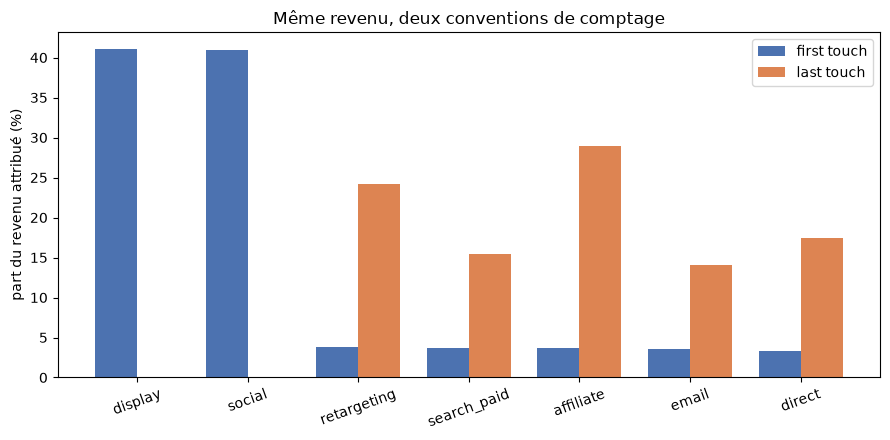

In [6]:
ordre = attribution.sort_values("first_touch_pct", ascending=False).index
positions = np.arange(len(ordre))
largeur = 0.38

figure, axe = plt.subplots(figsize=(9, 4.5))
axe.bar(positions - largeur / 2, attribution.loc[ordre, "first_touch_pct"],
        largeur, label="first touch", color="#4c72b0")
axe.bar(positions + largeur / 2, attribution.loc[ordre, "last_touch_pct"],
        largeur, label="last touch", color="#dd8452")

axe.set_xticks(positions, ordre, rotation=20)
axe.set_ylabel("part du revenu attribué (%)")
axe.set_title("Même revenu, deux conventions de comptage")
axe.legend()
plt.tight_layout()
plt.show()

## 3. Ce que ça change pour le budget

La question posée est concrète : si le CMO arbitrait sur le seul last touch,
quels canaux seraient sous-investis ?

In [7]:
BUDGET_ACTUEL = df_touchpoints["cost"].sum()

repartition = pd.DataFrame({
    "budget_actuel_eur": df_touchpoints.groupby("channel")["cost"].sum(),
    "si_first_touch_eur": (attribution["first_touch_pct"] / 100
                           * BUDGET_ACTUEL),
    "si_last_touch_eur": (attribution["last_touch_pct"] / 100
                          * BUDGET_ACTUEL),
})
repartition["part_actuelle_pct"] = (repartition["budget_actuel_eur"]
                                    / BUDGET_ACTUEL * 100).round(1)
for colonne in ["budget_actuel_eur", "si_first_touch_eur",
                "si_last_touch_eur"]:
    repartition[colonne] = repartition[colonne].round(0)

COLONNES = ["budget_actuel_eur", "part_actuelle_pct", "si_first_touch_eur",
            "si_last_touch_eur"]
repartition[COLONNES].sort_values("budget_actuel_eur", ascending=False)

,budget_actuel_eur,part_actuelle_pct,si_first_touch_eur,si_last_touch_eur
channel,,,,
affiliate,1128777.0,83.7,49876.0,389574.0
social,166324.0,12.3,551335.0,0.0
search_paid,47264.0,3.5,49876.0,207593.0
email,2263.0,0.2,48528.0,190069.0
retargeting,1898.0,0.1,51224.0,326218.0
display,1482.0,0.1,554031.0,0.0
direct,0.0,0.0,44484.0,234553.0


Trois écarts ressortent, et ils ne vont pas dans le même sens.

**Le budget actuel ne suit ni l'un ni l'autre des deux modèles.** L'affiliation
reçoit 83,7 % de la dépense alors qu'elle ne mérite que 28,9 % du crédit au last
touch, et 3,7 % au first touch. Quel que soit le modèle retenu, elle est
surinvestie — c'est la seule conclusion que les deux modèles partagent, et c'est
donc la plus solide.

**Display et social seraient purement supprimés sur un arbitrage last touch.**
Ils reçoivent aujourd'hui 12,4 % du budget. Le last touch leur attribue zéro
euro. Or ce sont eux qui ouvrent 81,7 % des parcours qui finissent par un achat.
Les couper reviendrait à supprimer la source d'entrée de huit acheteurs sur dix
pour économiser un huitième du budget.

**Le retargeting et l'email seraient sous-investis dans les deux lectures.** Ils
reçoivent 0,1 % et 0,2 % du budget pour 24,2 % et 14,1 % du crédit au last touch.
Ce sont les canaux les moins chers et parmi les plus efficaces, ce qui recoupe
leur ratio valeur sur coût du notebook précédent.

Cette lecture est cohérente avec le rôle réel de chaque canal. Display et social
font de la découverte : ils ne closent pas, ils alimentent. Affiliation,
retargeting, email et search interviennent en fin de parcours, sur des gens déjà
au courant. Juger les premiers sur la conversion revient à reprocher à une
vitrine de ne pas encaisser.

## 4. Et quand on n'a pas de vision croisée ?

Le cas de Lumina & Co est confortable : un seul fichier contient tous les points
de contact, avec un identifiant de parcours qui les relie. C'est ce qui rend la
comparaison possible.

Un auto-entrepreneur n'a pas ça. Ses chiffres vivent dans des outils séparés :
Meta Business Suite pour le social, Google Analytics pour le search, sa
plateforme d'emailing pour les newsletters. Chaque outil compte les conversions
qu'il estime avoir provoquées, avec ses propres règles et sa propre fenêtre
d'attribution. Deux conséquences.

**Les conversions sont comptées plusieurs fois.** Si un client voit une publicité
Instagram puis clique sur un email, Meta et l'outil d'emailing revendiquent tous
les deux la vente. En additionnant les rapports, on trouve plus de conversions
qu'on n'a de commandes. C'est exactement ce que décrit le CMO au début : le social
dit que tout marche, Google dit la même chose, et les ventes ne suivent pas.

**Chaque outil se juge lui-même au last touch.** Une régie n'a aucune visibilité
sur ce qui s'est passé avant son propre clic, et aucun intérêt à en avoir. Les
canaux de découverte sont donc structurellement invisibles dans ce dispositif.

Ce qu'on peut raisonnablement conclure sur un canal qu'on ne peut pas comparer
aux autres : presque rien sur sa contribution réelle. On peut mesurer sa
performance interne — combien coûte un clic, quel est le taux d'ouverture — mais
pas sa part dans une vente. Sans identifiant de parcours partagé, la question de
l'attribution ne se pose même pas.

## 5. Recommandation

**Sur ces données, je ne recommande pas de modèle unique.** Ni le first touch ni
le last touch ne décrivent ce qui se passe : le premier efface entièrement les
quatre canaux qui closent, le second efface entièrement les deux qui font
découvrir. Un écart de 41 points sur un même canal selon la convention retenue
n'est pas un détail méthodologique, c'est la preuve qu'aucune des deux ne peut
servir seule à arbitrer un budget.

**Je recommande un modèle multi-touch, et le linéaire pour commencer.** Il répartit
le crédit également entre toutes les étapes du parcours. Ce n'est pas le plus fin
— un modèle en U, qui donne 40 % au premier, 40 % au dernier et 20 % au reste,
correspondrait mieux à ce qu'on observe ici, où l'ouverture et la clôture
comptent visiblement plus que le milieu. Mais le linéaire a un avantage décisif
dans le contexte : il n'a aucun paramètre à justifier. Les 40/40/20 du modèle en U
sont des conventions, et il faudrait pouvoir les défendre devant le CMO.

**Ce qui est actionnable dès maintenant, sans choisir de modèle.** Trois
conclusions ne dépendent pas de la convention retenue, et ce sont celles à
présenter en premier :

L'affiliation est surinvestie dans les deux lectures, avec 83,7 % du budget pour
28,9 % du crédit au mieux, et un ratio valeur sur coût de 0,78 mesuré au notebook
précédent.

Le retargeting et l'email sont sous-investis dans les deux lectures, avec 0,3 %
du budget à eux deux pour plus d'un tiers du crédit au last touch.

Display et social ne doivent pas être arbitrés sur la conversion. Leur rôle est
mesurable autrement : ils ouvrent 81,7 % des parcours qui aboutissent. Le bon
indicateur pour eux n'est pas le ROAS mais leur part dans les entrées de parcours.

**Une limite à porter en présentation.** Tout ce raisonnement suppose que le
parcours enregistré est complet. Il ne l'est jamais vraiment : les points de
contact non traçables — une recommandation d'une amie, une vitrine, un article de
presse — n'y figurent pas. Le premier contact observé n'est donc pas le premier
contact réel. C'est une limite structurelle de l'attribution, pas un défaut de
ce jeu de données.